In [30]:
import pandas as pd

df = pd.read_csv("../data/raw/UpdatedResumeDataSet.csv")

df.head()

,Category,Resume
0,Data Science,Skills * Programming Languages: Python (pandas...
1,Data Science,Education Details \r\nMay 2013 to May 2017 B.E...
2,Data Science,"Areas of Interest Deep Learning, Control Syste..."
3,Data Science,Skills â¢ R â¢ Python â¢ SAP HANA â¢ Table...
4,Data Science,"Education Details \r\n MCA YMCAUST, Faridab..."


In [31]:
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (962, 2)

Columns: ['Category', 'Resume']

Missing values:
Category    0
Resume      0
dtype: int64


In [32]:
print("Number of job categories:", df["Category"].nunique())

print("\nJob categories:")
print(df["Category"].value_counts())

Number of job categories: 25

Job categories:
Category
Java Developer               84
Testing                      70
DevOps Engineer              55
Python Developer             48
Web Designing                45
HR                           44
Hadoop                       42
Data Science                 40
Mechanical Engineer          40
Sales                        40
Operations Manager           40
ETL Developer                40
Blockchain                   40
Arts                         36
Database                     33
Health and fitness           30
Electrical Engineering       30
PMO                          30
Business Analyst             28
DotNet Developer             28
Automation Testing           26
Network Security Engineer    25
Civil Engineer               24
SAP Developer                24
Advocate                     20
Name: count, dtype: int64


In [33]:
df["Category"].value_counts().head(10)


Category
Java Developer         84
Testing                70
DevOps Engineer        55
Python Developer       48
Web Designing          45
HR                     44
Hadoop                 42
Data Science           40
Mechanical Engineer    40
Sales                  40
Name: count, dtype: int64

In [34]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df["Clean_Resume"] = df["Resume"].apply(clean_text)

df[["Category", "Clean_Resume"]].head()

,Category,Clean_Resume
0,Data Science,skills programming languages python pandas num...
1,Data Science,education details may 2013 to may 2017 b e uit...
2,Data Science,areas of interest deep learning control system...
3,Data Science,skills r python sap hana tableau sap hana sql ...
4,Data Science,education details mca ymcaust faridabad haryan...


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["Clean_Resume"])
y = df["Category"]

print("TF-IDF shape:", X.shape)

TF-IDF shape: (962, 5000)


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 769
Testing samples: 193


In [36]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [37]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9948186528497409

Classification Report:
                           precision    recall  f1-score   support

                 Advocate       1.00      1.00      1.00         4
                     Arts       1.00      1.00      1.00         7
       Automation Testing       0.83      1.00      0.91         5
               Blockchain       1.00      1.00      1.00         8
         Business Analyst       1.00      1.00      1.00         6
           Civil Engineer       1.00      1.00      1.00         5
             Data Science       1.00      1.00      1.00         8
                 Database       1.00      1.00      1.00         7
          DevOps Engineer       1.00      0.91      0.95        11
         DotNet Developer       1.00      1.00      1.00         5
            ETL Developer       1.00      1.00      1.00         8
   Electrical Engineering       1.00      1.00      1.00         6
                       HR       1.00      1.00      1.00         9
        

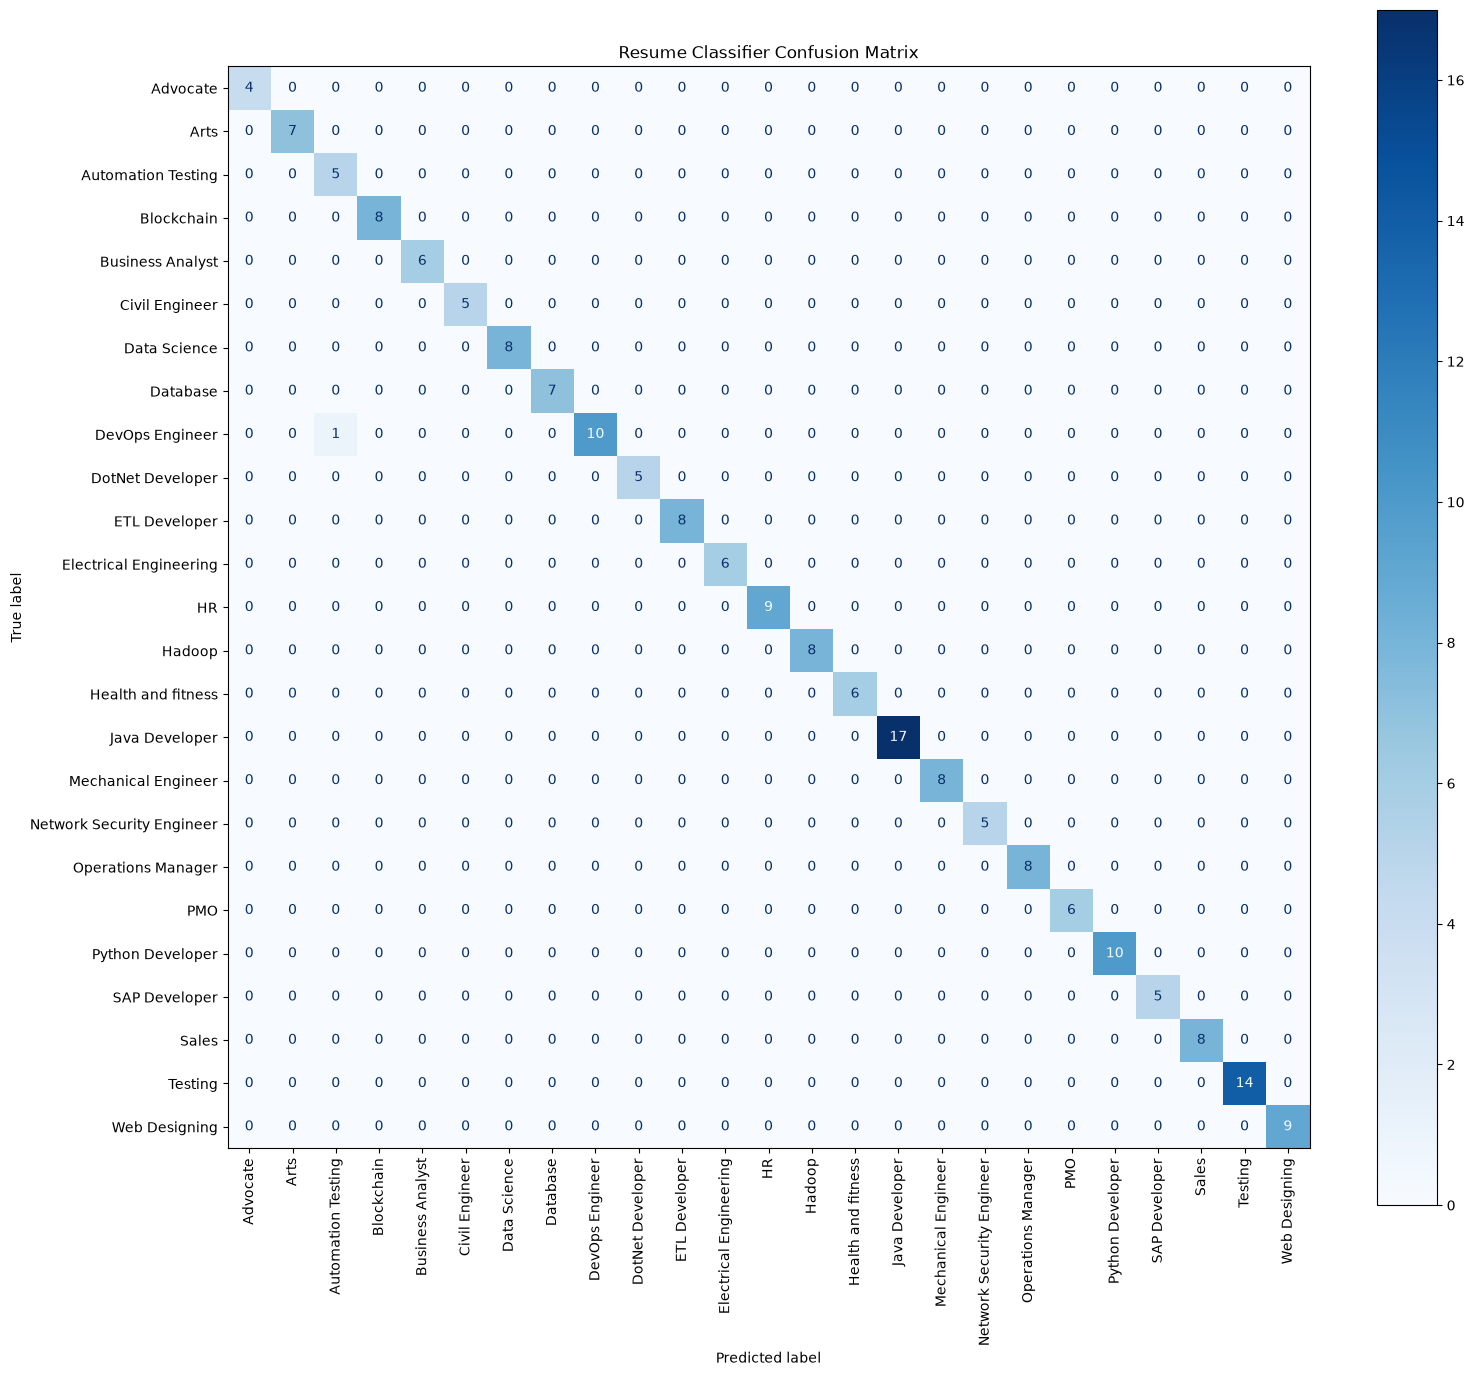

In [38]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(16, 14))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=90,
    values_format="d",
    cmap="Blues",
    ax=ax
)

plt.title("Resume Classifier Confusion Matrix")
plt.tight_layout()
plt.show()

In [39]:
fig.savefig(
    "../reports/figures/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

print("Confusion matrix saved.")

Confusion matrix saved.


In [40]:
import joblib

joblib.dump(model, "../models/classifier.pkl")
joblib.dump(tfidf, "../models/tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")

Model and TF-IDF vectorizer saved successfully.


In [41]:
new_resume = """
Python developer with experience in machine learning,
data analysis, pandas, numpy, scikit-learn and SQL.
"""

cleaned_resume = clean_text(new_resume)

resume_vector = tfidf.transform([cleaned_resume])

prediction = model.predict(resume_vector)

print("Predicted Job Category:", prediction[0])

Predicted Job Category: Data Science


In [42]:
jobs = pd.read_csv("../data/raw/job_recommendation_dataset.csv")

print("Job dataset shape:", jobs.shape)
print("\nColumns:")
print(jobs.columns.tolist())

Job dataset shape: (50000, 7)

Columns:
['Job Title', 'Company', 'Location', 'Experience Level', 'Salary', 'Industry', 'Required Skills']


In [43]:
print("Missing values:")
print(jobs.isnull().sum())

print("\nDuplicate rows:", jobs.duplicated().sum())

print("\nFirst 5 job listings:")
jobs.head()

Missing values:
Job Title           0
Company             0
Location            0
Experience Level    0
Salary              0
Industry            0
Required Skills     0
dtype: int64

Duplicate rows: 0

First 5 job listings:


,Job Title,Company,Location,Experience Level,Salary,Industry,Required Skills
0,Early years teacher,Richardson Ltd,Sydney,Senior Level,87000.0,Healthcare,Pharmaceuticals
1,Counselling psychologist,"Ramos, Santiago and Stewart",San Francisco,Mid Level,50000.0,Marketing,"Google Ads, SEO, Content Writing"
2,Radio broadcast assistant,Franco Group,New York,Mid Level,77000.0,Healthcare,"Patient Care, Nursing, Medical Research, Pharm..."
3,"Designer, exhibition/display",Collins Inc,Berlin,Senior Level,90000.0,Software,Machine Learning
4,"Psychotherapist, dance movement",Barker Group,Sydney,Entry Level,112000.0,Healthcare,"Nursing, Medical Research, Pharmaceuticals"


In [44]:
jobs["Job_Text"] = (
    jobs["Job Title"].astype(str) + " " +
    jobs["Industry"].astype(str) + " " +
    jobs["Required Skills"].astype(str)
)

jobs[["Job Title", "Industry", "Required Skills", "Job_Text"]].head()

,Job Title,Industry,Required Skills,Job_Text
0,Early years teacher,Healthcare,Pharmaceuticals,Early years teacher Healthcare Pharmaceuticals
1,Counselling psychologist,Marketing,"Google Ads, SEO, Content Writing","Counselling psychologist Marketing Google Ads,..."
2,Radio broadcast assistant,Healthcare,"Patient Care, Nursing, Medical Research, Pharm...",Radio broadcast assistant Healthcare Patient C...
3,"Designer, exhibition/display",Software,Machine Learning,"Designer, exhibition/display Software Machine ..."
4,"Psychotherapist, dance movement",Healthcare,"Nursing, Medical Research, Pharmaceuticals","Psychotherapist, dance movement Healthcare Nur..."


In [45]:
print(jobs.columns.tolist())

['Job Title', 'Company', 'Location', 'Experience Level', 'Salary', 'Industry', 'Required Skills', 'Job_Text']


In [46]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=7, random_state=42, n_init=10)
jobs["Cluster"] = kmeans.fit_predict(job_vectors)

for cluster in sorted(jobs["Cluster"].unique()):
    cluster_data = jobs[jobs["Cluster"] == cluster]

    print(f"\n===== Cluster {cluster} =====")
    print("\nTop Industries:")
    print(cluster_data["Industry"].value_counts().head(5))

    print("\nTop Job Titles:")
    print(cluster_data["Job Title"].value_counts().head(5))


===== Cluster 0 =====

Top Industries:
Industry
Software    7300
Name: count, dtype: int64

Top Job Titles:
Job Title
Ecologist                                 26
Research scientist (physical sciences)    24
Surveyor, minerals                        22
Systems developer                         21
Environmental health practitioner         21
Name: count, dtype: int64

===== Cluster 1 =====

Top Industries:
Industry
Education    7143
Name: count, dtype: int64

Top Job Titles:
Job Title
Lobbyist                              25
Development worker, community         21
Public relations account executive    21
Engineer, electrical                  21
Surveyor, hydrographic                20
Name: count, dtype: int64

===== Cluster 2 =====

Top Industries:
Industry
Manufacturing    7169
Name: count, dtype: int64

Top Job Titles:
Job Title
Agricultural engineer                  21
Learning mentor                        21
Administrator, sports                  21
Chartered public finance acco

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer

jobs["Cluster_Text"] = (
    jobs["Job Title"].astype(str) + " " +
    jobs["Required Skills"].astype(str) + " " +
    jobs["Experience Level"].astype(str)
)

cluster_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

cluster_vectors = cluster_tfidf.fit_transform(
    jobs["Cluster_Text"]
)

print("Clustering features created.")
print("Shape:", cluster_vectors.shape)

Clustering features created.
Shape: (50000, 540)


In [48]:
from sklearn.cluster import KMeans

cluster_kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

new_cluster_labels = cluster_kmeans.fit_predict(cluster_vectors)

jobs["New_Cluster"] = new_cluster_labels

print("New clustering completed.")
print("Number of clusters:", jobs["New_Cluster"].nunique())

New clustering completed.
Number of clusters: 7


In [49]:
for cluster in sorted(jobs["New_Cluster"].unique()):

    cluster_data = jobs[jobs["New_Cluster"] == cluster]

    print(f"\n===== New Cluster {cluster} =====")

    print("\nTop Industries:")
    print(cluster_data["Industry"].value_counts().head(3))

    print("\nTop Job Titles:")
    print(cluster_data["Job Title"].value_counts().head(5))


===== New Cluster 0 =====

Top Industries:
Industry
Retail        5932
Healthcare       4
Software         4
Name: count, dtype: int64

Top Job Titles:
Job Title
Customer service manager              35
Records manager                       19
Logistics and distribution manager    19
Research scientist (medical)          18
Chief Strategy Officer                18
Name: count, dtype: int64

===== New Cluster 1 =====

Top Industries:
Industry
Manufacturing    6417
Name: count, dtype: int64

Top Job Titles:
Job Title
Agricultural engineer       21
Administrator, sports       21
Scientist, marine           21
Psychiatrist                20
Educational psychologist    19
Name: count, dtype: int64

===== New Cluster 2 =====

Top Industries:
Industry
Healthcare    5780
Marketing        3
Retail           2
Name: count, dtype: int64

Top Job Titles:
Job Title
Radio broadcast assistant    21
Facilities manager           20
Advertising copywriter       19
Site engineer                18
Art th

In [50]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# Create role-focused text for clustering
jobs["Role_Cluster_Text"] = (
    jobs["Job Title"].astype(str) + " " +
    jobs["Job Title"].astype(str) + " " +
    jobs["Required Skills"].astype(str)
)

role_tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000
)

role_vectors = role_tfidf.fit_transform(
    jobs["Role_Cluster_Text"]
)

role_kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

jobs["Role_Cluster"] = role_kmeans.fit_predict(role_vectors)

print("Role-focused clustering completed.")
print("Number of clusters:", jobs["Role_Cluster"].nunique())

for cluster in sorted(jobs["Role_Cluster"].unique()):

    cluster_data = jobs[jobs["Role_Cluster"] == cluster]

    print(f"\n===== Role Cluster {cluster} =====")
    print(cluster_data["Job Title"].value_counts().head(5))

Role-focused clustering completed.
Number of clusters: 7

===== Role Cluster 0 =====
Job Title
Chartered legal executive (England and Wales)    79
Programme researcher, broadcasting/film/video    71
Chartered public finance accountant              70
Senior tax professional/tax inspector            69
Teacher, English as a foreign language           68
Name: count, dtype: int64

===== Role Cluster 1 =====
Job Title
Quarry manager               87
Location manager             87
Conference centre manager    86
Facilities manager           85
Risk manager                 85
Name: count, dtype: int64

===== Role Cluster 2 =====
Job Title
Research scientist (physical sciences)     90
Scientist, audiological                    84
Research scientist (medical)               75
Water quality scientist                    74
Scientist, research (physical sciences)    74
Name: count, dtype: int64

===== Role Cluster 3 =====
Job Title
Jewellery designer                     92
Set designer         

In [52]:
job_clusters = jobs["Cluster"].values

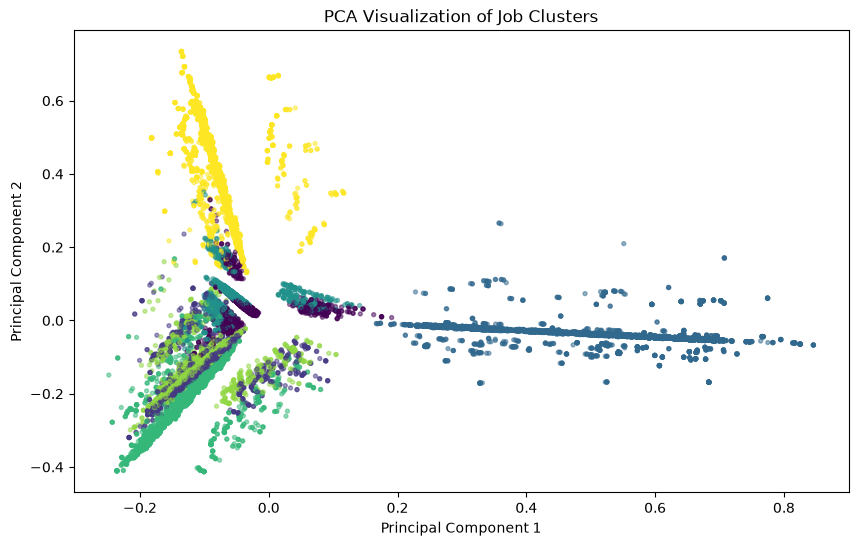

In [53]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)

job_pca = pca.fit_transform(job_vectors.toarray())

plt.figure(figsize=(10, 6))

plt.scatter(
    job_pca[:, 0],
    job_pca[:, 1],
    c=job_clusters,
    s=8,
    alpha=0.5
)

plt.title("PCA Visualization of Job Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

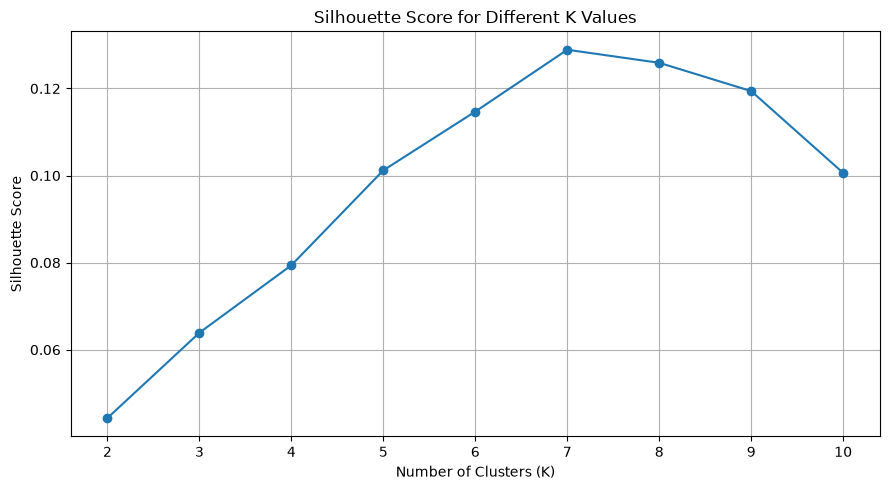

In [54]:
import matplotlib.pyplot as plt

k_values = list(range(2, 11))

# Previously calculated silhouette scores
scores = [
    0.0443, 0.0639, 0.0794, 0.1012, 0.1147,
    0.1289, 0.1259, 0.1194, 0.1006
]

plt.figure(figsize=(9, 5))
plt.plot(k_values, scores, marker="o")

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

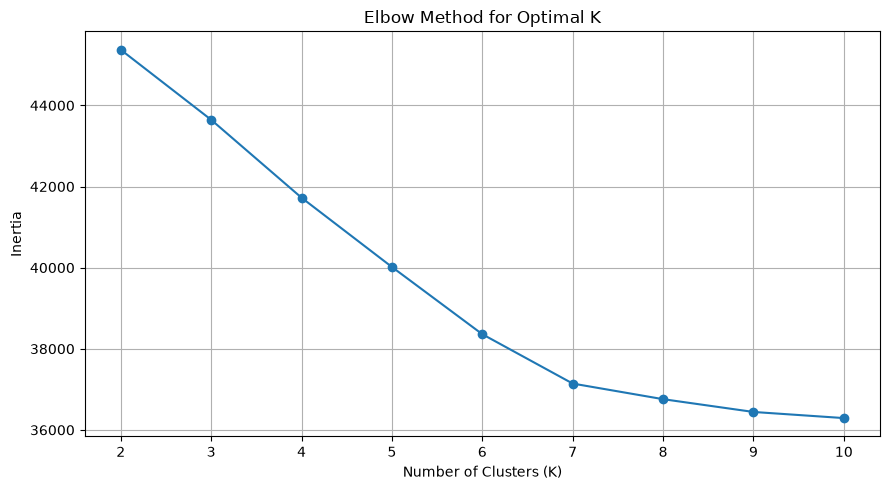

In [55]:
import matplotlib.pyplot as plt

k_values = list(range(2, 11))

inertias = [
    45372.1811, 43645.7120, 41724.3992,
    40016.8203, 38359.3982, 37142.7466,
    36757.7690, 36442.5499, 36291.5999
]

plt.figure(figsize=(9, 5))
plt.plot(k_values, inertias, marker="o")

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.tight_layout()
plt.show()

In [56]:
from sklearn.feature_extraction.text import TfidfVectorizer

job_tfidf = TfidfVectorizer(max_features=5000)

job_vectors = job_tfidf.fit_transform(jobs["Job_Text"])

print("Job TF-IDF shape:", job_vectors.shape)

Job TF-IDF shape: (50000, 544)


In [57]:
from sklearn.metrics.pairwise import cosine_similarity

resume_text = df["Clean_Resume"].iloc[0]

resume_vector = job_tfidf.transform([resume_text])

similarities = cosine_similarity(resume_vector, job_vectors).flatten()

print("Number of job similarity scores:", len(similarities))
print("Highest similarity score:", similarities.max())

Number of job similarity scores: 50000
Highest similarity score: 0.3893658059980963


In [58]:
top_indices = similarities.argsort()[-10:][::-1]

top_jobs = jobs.iloc[top_indices].copy()

top_jobs["Match Score"] = similarities[top_indices]

top_jobs[
    ["Job Title", "Company", "Location", "Industry", "Required Skills", "Match Score"]
]

,Job Title,Company,Location,Industry,Required Skills,Match Score
41686,Chief of Staff,Baker PLC,Bangalore,Finance,Risk Analysis,0.389366
9115,Chief of Staff,"Leonard, Haney and Davis",San Francisco,Finance,"Excel, Python, Risk Analysis",0.387217
18235,Chief of Staff,"Wagner, Cook and Santiago",Sydney,Software,Python,0.384020
25717,Chief of Staff,Walker-Craig,Bangalore,Software,"Java, Python",0.372533
39241,Chief of Staff,"Daniels, Cooper and Johnson",Bangalore,Software,C++,0.372056
20080,Chief of Staff,Clark-Russell,Sydney,Finance,"Python, SQL, Financial Modeling, Risk Analysis",0.370440
48294,Chief of Staff,"Crosby, Manning and Avila",San Francisco,Finance,"Python, Risk Analysis, SQL, Financial Modeling",0.370440
10880,Chief of Staff,Barton PLC,Sydney,Finance,"Risk Analysis, Excel, Financial Modeling, Python",0.364160
46970,Chief of Staff,Brown-Mcgrath,Bangalore,Finance,"Financial Modeling, Risk Analysis",0.363471
45785,Chief of Staff,Levy-Martin,Sydney,Software,"SQL, Python, Machine Learning",0.363072


In [59]:
top_jobs["Match Percentage"] = (top_jobs["Match Score"] * 100).round(2)

top_jobs[
    ["Job Title", "Company", "Location", "Industry", "Match Percentage"]
]

,Job Title,Company,Location,Industry,Match Percentage
41686,Chief of Staff,Baker PLC,Bangalore,Finance,38.94
9115,Chief of Staff,"Leonard, Haney and Davis",San Francisco,Finance,38.72
18235,Chief of Staff,"Wagner, Cook and Santiago",Sydney,Software,38.40
25717,Chief of Staff,Walker-Craig,Bangalore,Software,37.25
39241,Chief of Staff,"Daniels, Cooper and Johnson",Bangalore,Software,37.21
20080,Chief of Staff,Clark-Russell,Sydney,Finance,37.04
48294,Chief of Staff,"Crosby, Manning and Avila",San Francisco,Finance,37.04
10880,Chief of Staff,Barton PLC,Sydney,Finance,36.42
46970,Chief of Staff,Brown-Mcgrath,Bangalore,Finance,36.35
45785,Chief of Staff,Levy-Martin,Sydney,Software,36.31


In [60]:
best_job = top_jobs.iloc[0]

print("Target Job:", best_job["Job Title"])
print("Required Skills:", best_job["Required Skills"])

Target Job: Chief of Staff
Required Skills: Risk Analysis


In [61]:
resume_text = df["Clean_Resume"].iloc[0]

skills = [
    "python", "java", "sql", "machine learning", "deep learning",
    "data analysis", "pandas", "numpy", "scikit learn",
    "tensorflow", "excel", "risk analysis", "communication"
]

resume_skills = []

for skill in skills:
    if skill in resume_text:
        resume_skills.append(skill)

print("Skills found in resume:")
print(resume_skills)

Skills found in resume:
['python', 'java', 'sql', 'machine learning', 'deep learning', 'pandas', 'numpy', 'scikit learn']


In [ ]:
required_skills = [
    skill.strip().lower()
    for skill in best_job["Required Skills"].split(",")
]

missing_skills = [
    skill for skill in required_skills
    if skill not in resume_skills
]

print("Resume Skills:", resume_skills)
print("Required Skills:", required_skills)
print("Missing Skills:", missing_skills)

Resume Skills: ['python', 'java', 'sql', 'machine learning', 'deep learning', 'pandas', 'numpy', 'scikit learn']
Required Skills: ['risk analysis']
Missing Skills: ['risk analysis']


In [62]:
target_job = top_jobs.iloc[-1]

print("Target Job:", target_job["Job Title"])
print("Required Skills:", target_job["Required Skills"])

Target Job: Chief of Staff
Required Skills: SQL, Python, Machine Learning


In [63]:
required_skills = [
    skill.strip().lower()
    for skill in target_job["Required Skills"].split(",")
]

missing_skills = [
    skill for skill in required_skills
    if skill not in resume_skills
]

matched_skills = [
    skill for skill in required_skills
    if skill in resume_skills
]

print("Matched Skills:", matched_skills)
print("Missing Skills:", missing_skills)

Matched Skills: ['sql', 'python', 'machine learning']
Missing Skills: []


In [64]:
if len(required_skills) > 0:
    skill_match_percentage = (
        len(matched_skills) / len(required_skills)
    ) * 100
else:
    skill_match_percentage = 0

print("Skill Match Percentage:", round(skill_match_percentage, 2), "%")

Skill Match Percentage: 100.0 %


In [65]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

job_clusters = kmeans.fit_predict(job_vectors)

jobs["Cluster"] = job_clusters

print("Clustering completed.")
print("Number of clusters:", jobs["Cluster"].nunique())

Clustering completed.
Number of clusters: 5


In [66]:
from sklearn.metrics import silhouette_score

silhouette = silhouette_score(job_vectors, job_clusters)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.101


In [67]:
inertias = []

for k in range(2, 11):
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans_temp.fit(job_vectors)
    inertias.append(kmeans_temp.inertia_)

print("K values:", list(range(2, 11)))
print("Inertia values:", inertias)

K values: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Inertia values: [45372.18114338138, 43645.71204012755, 41724.39923883477, 40016.82032511726, 38359.39822294805, 37142.74659006472, 36757.769028357936, 36442.54988146312, 36291.59996715448]


In [68]:
import joblib
import pandas as pd

job_tfidf = joblib.load("../models/job_tfidf_vectorizer.pkl")
jobs = pd.read_csv("../data/processed/processed_jobs.csv")

In [ ]:
job_vectors = job_tfidf.transform(jobs["Job_Text"])

In [69]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score 
silhouette_scores = []

for k in range(2, 11):
    kmeans_temp = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans_temp.fit_predict(job_vectors)

    score = silhouette_score(
        job_vectors,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: Silhouette Score={score:.4f}")
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K={k}: Silhouette Score={score:.4f}")


K=2: Silhouette Score=0.0468
K=3: Silhouette Score=0.0639
K=4: Silhouette Score=0.0834
K=5: Silhouette Score=0.1023
K=6: Silhouette Score=0.1191
K=7: Silhouette Score=0.1289
K=8: Silhouette Score=0.1259
K=9: Silhouette Score=0.1194
K=10: Silhouette Score=0.1006
K=2: Silhouette Score=0.0468
K=3: Silhouette Score=0.0639
K=4: Silhouette Score=0.0834
K=5: Silhouette Score=0.1023
K=6: Silhouette Score=0.1191
K=7: Silhouette Score=0.1289
K=8: Silhouette Score=0.1259
K=9: Silhouette Score=0.1194
K=10: Silhouette Score=0.1006


In [70]:
import pandas as pd
import joblib
from sklearn.cluster import KMeans

job_tfidf = joblib.load("../models/job_tfidf_vectorizer.pkl")
jobs = pd.read_csv("../data/processed/processed_jobs.csv")

job_vectors = job_tfidf.transform(jobs["Job_Text"])

kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

job_clusters = kmeans.fit_predict(job_vectors)

jobs["Cluster"] = job_clusters

joblib.dump(kmeans, "../models/job_kmeans.pkl")

print("Final K-Means clustering completed.")
print("Number of clusters:", jobs["Cluster"].nunique())
print("\nJobs in each cluster:")
print(jobs["Cluster"].value_counts().sort_index())
print("\nFinal K-Means model saved successfully.")

Final K-Means clustering completed.
Number of clusters: 7

Jobs in each cluster:
Cluster
0    7300
1    7143
2    7169
3    7017
4    7104
5    7157
6    7110
Name: count, dtype: int64

Final K-Means model saved successfully.


In [71]:
# Check the most common job titles in each cluster

for cluster in sorted(jobs["Cluster"].unique()):
    print(f"\n--- Cluster {cluster} ---")
    print(
        jobs[jobs["Cluster"] == cluster]["Job Title"]
        .value_counts()
        .head(5)
    )


--- Cluster 0 ---
Job Title
Ecologist                                 26
Research scientist (physical sciences)    24
Surveyor, minerals                        22
Systems developer                         21
Environmental health practitioner         21
Name: count, dtype: int64

--- Cluster 1 ---
Job Title
Lobbyist                              25
Development worker, community         21
Public relations account executive    21
Engineer, electrical                  21
Surveyor, hydrographic                20
Name: count, dtype: int64

--- Cluster 2 ---
Job Title
Agricultural engineer                  21
Learning mentor                        21
Administrator, sports                  21
Chartered public finance accountant    21
Scientist, marine                      21
Name: count, dtype: int64

--- Cluster 3 ---
Job Title
Museum/gallery exhibitions officer    20
Interior and spatial designer         19
Personnel officer                     19
Radiation protection practitioner     19
Ma

In [72]:
# Show top job titles and industries for every cluster

for cluster in sorted(jobs["Cluster"].unique()):
    cluster_data = jobs[jobs["Cluster"] == cluster]

    print(f"\n========== CLUSTER {cluster} ==========")

    print("\nTop Job Titles:")
    print(cluster_data["Job Title"].value_counts().head(5))

    print("\nTop Industries:")
    print(cluster_data["Industry"].value_counts().head(5))


========== CLUSTER 0 ==========

Top Job Titles:
Job Title
Ecologist                                 26
Research scientist (physical sciences)    24
Surveyor, minerals                        22
Systems developer                         21
Environmental health practitioner         21
Name: count, dtype: int64

Top Industries:
Industry
Software    7300
Name: count, dtype: int64

========== CLUSTER 1 ==========

Top Job Titles:
Job Title
Lobbyist                              25
Development worker, community         21
Public relations account executive    21
Engineer, electrical                  21
Surveyor, hydrographic                20
Name: count, dtype: int64

Top Industries:
Industry
Education    7143
Name: count, dtype: int64

========== CLUSTER 2 ==========

Top Job Titles:
Job Title
Agricultural engineer                  21
Learning mentor                        21
Administrator, sports                  21
Chartered public finance accountant    21
Scientist, marine              

In [73]:
# Compact cluster summary

for cluster in sorted(jobs["Cluster"].unique()):
    cluster_data = jobs[jobs["Cluster"] == cluster]

    print(
        f"Cluster {cluster}: "
        f"{len(cluster_data)} jobs | "
        f"Top Industry: {cluster_data['Industry'].value_counts().index[0]} | "
        f"Top Job Titles: "
        f"{', '.join(cluster_data['Job Title'].value_counts().head(3).index)}"
    )

Cluster 0: 7300 jobs | Top Industry: Software | Top Job Titles: Ecologist, Research scientist (physical sciences), Surveyor, minerals
Cluster 1: 7143 jobs | Top Industry: Education | Top Job Titles: Lobbyist, Development worker, community, Public relations account executive
Cluster 2: 7169 jobs | Top Industry: Manufacturing | Top Job Titles: Agricultural engineer, Learning mentor, Administrator, sports
Cluster 3: 7017 jobs | Top Industry: Finance | Top Job Titles: Museum/gallery exhibitions officer, Interior and spatial designer, Personnel officer
Cluster 4: 7104 jobs | Top Industry: Healthcare | Top Job Titles: Facilities manager, Radio broadcast assistant, Designer, industrial/product
Cluster 5: 7157 jobs | Top Industry: Marketing | Top Job Titles: Waste management officer, Psychologist, clinical, Agricultural consultant
Cluster 6: 7110 jobs | Top Industry: Retail | Top Job Titles: Surveyor, building, Chief Strategy Officer, Records manager


In [74]:
# Build a skill vocabulary from the job dataset

all_skills = set()

for skills_text in jobs["Required Skills"]:
    for skill in str(skills_text).split(","):
        skill = skill.strip().lower()
        if skill:
            all_skills.add(skill)

skill_vocabulary = sorted(all_skills)

print("Total unique skills found:", len(skill_vocabulary))
print("\nFirst 30 skills:")
print(skill_vocabulary[:30])

Total unique skills found: 29

First 30 skills:
['aws', 'c++', 'content writing', 'curriculum design', 'customer service', 'edtech', 'excel', 'financial modeling', 'google ads', 'java', 'machine learning', 'market research', 'medical research', 'merchandising', 'nursing', 'patient care', 'pharmaceuticals', 'production planning', 'python', 'quality control', 'react', 'research', 'risk analysis', 'sales', 'seo', 'social media', 'sql', 'supply chain', 'teaching']


In [75]:
# Automatically detect skills in the resume

resume_text = df["Clean_Resume"].iloc[0]

resume_skills = []

for skill in skill_vocabulary:
    if skill in resume_text:
        resume_skills.append(skill)

print("Skills detected in resume:")
print(resume_skills)

Skills detected in resume:
['java', 'machine learning', 'python', 'research', 'sql']


In [76]:
# Compare resume skills with the best recommended job

best_job = top_jobs.iloc[0]

required_skills = [
    skill.strip().lower()
    for skill in str(best_job["Required Skills"]).split(",")
    if skill.strip()
]

matched_skills = [
    skill for skill in required_skills
    if skill in resume_skills
]

missing_skills = [
    skill for skill in required_skills
    if skill not in resume_skills
]

print("Target Job:", best_job["Job Title"])
print("Required Skills:", required_skills)
print("Matched Skills:", matched_skills)
print("Missing Skills:", missing_skills)

Target Job: Chief of Staff
Required Skills: ['risk analysis']
Matched Skills: []
Missing Skills: ['risk analysis']


In [77]:
# Calculate skill match percentage

if required_skills:
    skill_match_percentage = (
        len(matched_skills) / len(required_skills)
    ) * 100
else:
    skill_match_percentage = 0

print("Skill Match Percentage:", round(skill_match_percentage, 2), "%")

Skill Match Percentage: 0.0 %


In [78]:
# Recreate the final 7-cluster model

kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

job_clusters = kmeans.fit_predict(job_vectors)

jobs["Cluster"] = job_clusters

print("Cluster column restored.")
print("Number of clusters:", jobs["Cluster"].nunique())

Cluster column restored.
Number of clusters: 7


In [79]:
# Get the cluster of the best recommended job

best_job_index = top_jobs.index[0]
target_cluster = int(jobs.loc[best_job_index, "Cluster"])

cluster_jobs = jobs[jobs["Cluster"] == target_cluster]

cluster_skills = []

for skills_text in cluster_jobs["Required Skills"]:
    for skill in str(skills_text).split(","):
        skill = skill.strip().lower()
        if skill:
            cluster_skills.append(skill)

cluster_skill_counts = pd.Series(cluster_skills).value_counts()

print("Target Cluster:", target_cluster)
print("\nTop skills in this cluster:")
print(cluster_skill_counts.head(10))

Target Cluster: 3

Top skills in this cluster:
excel                 3573
risk analysis         3533
sql                   3521
python                3517
financial modeling    3444
c++                      1
Name: count, dtype: int64


In [80]:
# Compare resume skills with the top skills of the target cluster

top_cluster_skills = cluster_skill_counts.head(5).index.tolist()

cluster_matched_skills = [
    skill for skill in top_cluster_skills
    if skill in resume_skills
]

cluster_missing_skills = [
    skill for skill in top_cluster_skills
    if skill not in resume_skills
]

cluster_skill_match = (
    len(cluster_matched_skills) / len(top_cluster_skills) * 100
    if top_cluster_skills else 0
)

print("Target Cluster:", target_cluster)
print("Top Cluster Skills:", top_cluster_skills)
print("Matched Skills:", cluster_matched_skills)
print("Missing Skills:", cluster_missing_skills)
print("Cluster Skill Match:", round(cluster_skill_match, 2), "%")

Target Cluster: 3
Top Cluster Skills: ['excel', 'risk analysis', 'sql', 'python', 'financial modeling']
Matched Skills: ['sql', 'python']
Missing Skills: ['excel', 'risk analysis', 'financial modeling']
Cluster Skill Match: 40.0 %


In [81]:
# Qualitative evaluation of top job recommendations

print("Top 10 Recommended Jobs:")
print()

for i, (_, row) in enumerate(top_jobs.iterrows(), start=1):
    print(
        f"{i}. {row['Job Title']} | "
        f"{row['Industry']} | "
        f"Match: {row['Match Percentage']}%"
    )

Top 10 Recommended Jobs:

1. Chief of Staff | Finance | Match: 38.94%
2. Chief of Staff | Finance | Match: 38.72%
3. Chief of Staff | Software | Match: 38.4%
4. Chief of Staff | Software | Match: 37.25%
5. Chief of Staff | Software | Match: 37.21%
6. Chief of Staff | Finance | Match: 37.04%
7. Chief of Staff | Finance | Match: 37.04%
8. Chief of Staff | Finance | Match: 36.42%
9. Chief of Staff | Finance | Match: 36.35%
10. Chief of Staff | Software | Match: 36.31%


In [82]:
# Save recommender artifacts

joblib.dump(job_tfidf, "../models/job_tfidf_vectorizer.pkl")
joblib.dump(kmeans, "../models/job_kmeans.pkl")

jobs.to_csv("../data/processed/processed_jobs.csv", index=False)

print("Recommender artifacts saved successfully.")

Recommender artifacts saved successfully.


In [83]:
import os

files_to_check = [
    "../models/classifier.pkl",
    "../models/tfidf_vectorizer.pkl",
    "../models/job_tfidf_vectorizer.pkl",
    "../models/job_kmeans.pkl",
    "../data/processed/processed_jobs.csv"
]

for file in files_to_check:
    print(file, "->", "FOUND" if os.path.exists(file) else "MISSING")

../models/classifier.pkl -> FOUND
../models/tfidf_vectorizer.pkl -> FOUND
../models/job_tfidf_vectorizer.pkl -> FOUND
../models/job_kmeans.pkl -> FOUND
../data/processed/processed_jobs.csv -> FOUND


In [84]:
import joblib

joblib.dump(job_tfidf, "../models/job_tfidf_vectorizer.pkl")

print("Job TF-IDF vectorizer saved successfully.")

Job TF-IDF vectorizer saved successfully.


In [85]:
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np

# Get class probabilities from the trained classifier
y_proba = model.predict_proba(X_test)

# Convert actual labels into one-vs-rest binary labels
classes = model.classes_
y_test_bin = label_binarize(y_test, classes=classes)

# Calculate ROC-AUC for multiclass classification
roc_auc = roc_auc_score(
    y_test_bin,
    y_proba,
    multi_class="ovr",
    average="weighted"
)

print("Weighted ROC-AUC Score:", round(roc_auc, 4))


Weighted ROC-AUC Score: 1.0


In [86]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training and testing split completed.")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Training and testing split completed.
X_train: (769, 5000)
X_test: (193, 5000)
